# MeerKLASS 2019 L-band data $\times$ WiggleZ: cross-correlation with `meer21cm`

*Runtime: about 6 s on a MacBook (Apple M2), excluding the transfer function section; the transfer function section takes about 11 min (about 5 min for the 200 realisations in Section 5 and 6 min for the parameter fit in Section 6).*

This notebook follows the `meer21cm` cookbook [2019 L-band cross-correlation analysis](https://meer21cm.readthedocs.io/en/latest/cookbook/2019_Lband.html). It measures the cross-power spectrum between the MeerKLASS 2019 L-band HI intensity maps and the WiggleZ galaxies in the 11-hr field, corrects it for signal loss from foreground cleaning with a transfer function, and fits the HI density and beam size.

A detailed description of each step is given in the [2021 L-band $\times$ GAMA cookbook](https://meer21cm.readthedocs.io/en/latest/cookbook/2021_Lband_gama_cross.html).

## Data

Put both files in a folder `data/` next to this notebook:

* `MK_2019_maps.pkl`: the MeerKLASS 2019 L-band maps, from the MeerKLASS public data release at https://meerklass.org/data.html .
* `reg11data.dat`: the WiggleZ galaxy catalogue for the 11-hr field ($0.3<z<0.5$), from the workshop Google Drive folder: https://drive.google.com/drive/folders/1D1XHOaCy8WdOLfYLCpvVhSSa_sr0bgyQ?usp=sharing (see the README there for the papers to cite).

In [1]:
from meer21cm import PowerSpectrum
import matplotlib.pyplot as plt
import numpy as np
from meer21cm.util import pca_clean
from meer21cm.telescope import dish_beam_sigma
from meer21cm.util import center_to_edges
from meer21cm.plot import plot_map, plot_eigenspectrum
from meer21cm.inference import SamplerEmcee, extract_model_fitting_inputs
from meer21cm.transfer import TransferFunction
from meer21cm.grid import shot_noise_correction_from_gridding
from meer21cm.power import get_shot_noise_galaxy



In [2]:
# Plot style for a projected screen: larger fonts and one default figure size for all plots
plt.rcParams.update({
    'figure.figsize': (8, 5.5), # default figure size [inches]
    'font.size': 13, # default text size
    'axes.labelsize': 15, # axis labels
    'axes.titlesize': 14, # titles
    'xtick.labelsize': 13, # tick labels
    'ytick.labelsize': 13,
    'legend.fontsize': 12, # legends
})

## 1. Read the maps and the galaxy catalogue

In [3]:
file_dir = './data/' # folder holding the two data files
pickle_file = file_dir+'MK_2019_maps.pkl' # MeerKLASS 2019 maps
gal_file = file_dir+'reg11data.dat' # WiggleZ catalogue: RA, Dec, z, r-mag, jack-knife region, weight

ps = PowerSpectrum(
    pickle_file=pickle_file, # file with the maps, weights and frequencies
    #gal_file=gal_file,
    beam_model='gaussian', # Gaussian beam profile
    beam_type='isotropic', # same beam width in both sky directions
    band='L', # MeerKAT L-band
    survey='meerklass_2019', # survey settings for the 2019 data
)
# read in map_file
ps.read_from_pickle()
# read in galaxy positions
galcat = np.genfromtxt(gal_file, skip_header=1) # skip_header: skip the first line (number of galaxies)
ra_g,dec_g,z_g = galcat[:,0],galcat[:,1],galcat[:,2]
ps._ra_gal = ra_g
ps._dec_gal = dec_g
ps._z_gal = z_g
D_dish = 13.5 # Dish-diameter [metres]
sigma_ch = dish_beam_sigma(D_dish,ps.nu,) # beam width in each frequency channel
ps.sigma_beam_ch = sigma_ch


filtering map los


In [4]:
# this is just for plotting the contour below
temp = PowerSpectrum(
    pickle_file=pickle_file,
    #gal_file=gal_file,
    beam_model='gaussian',
    beam_type='isotropic',
    band='L',
    survey='meerklass_2019',
)
temp.read_from_pickle()
temp.W_HI = np.ones_like(temp.W_HI)
temp.ra_range = np.array([153,172]) # RA range [deg]
temp.dec_range = np.array([0.5,6.6]) # Dec range [deg]
temp.trim_map_to_range()

filtering map los


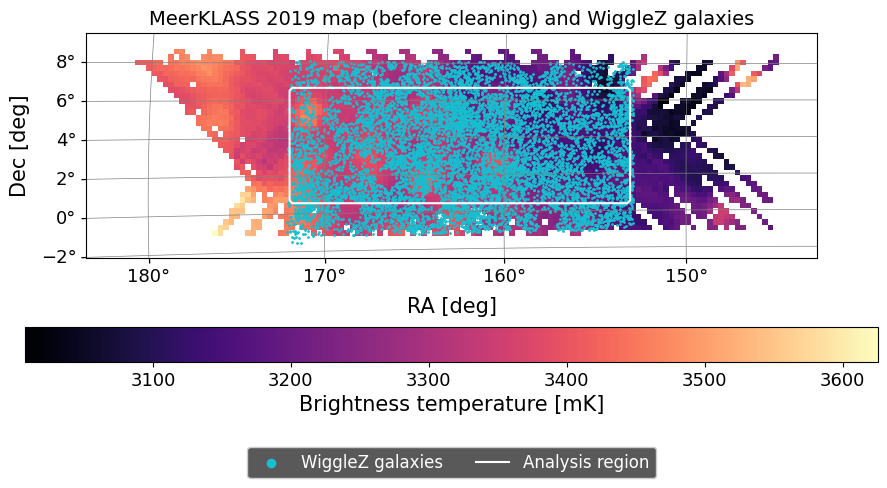

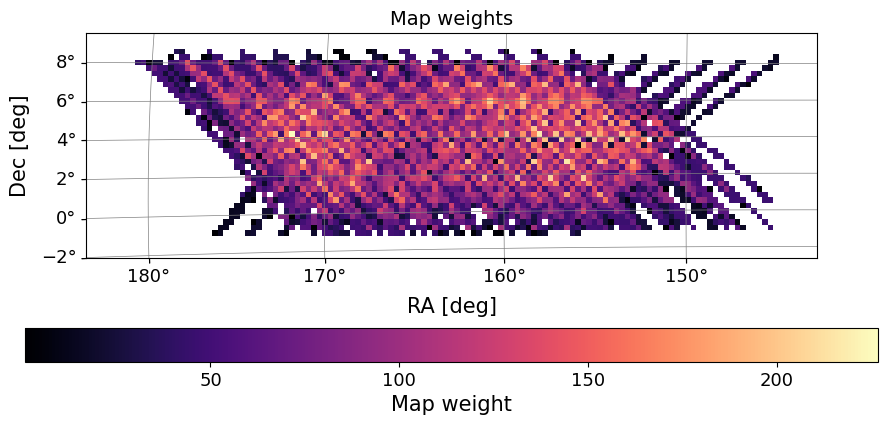

In [5]:
# map of the full survey area, averaged over frequency, with the WiggleZ galaxies on top
fig = plt.figure(figsize=(11, 4.5)) # figure size [inches]
ax = fig.add_subplot(projection=ps.wproj) # axes in sky coordinates
plot_map(
    ps.data*1e3, ps.wproj, W=ps.W_HI, # map in mK, sky projection, binary mask W
    cbar_label='Brightness temperature [mK]', # colour-bar label
    title='MeerKLASS 2019 map (before cleaning) and WiggleZ galaxies', # plot title
    ax=ax, # draw on the axes made above
)
ax.scatter(
    ps.ra_gal,
    ps.dec_gal,
    transform=ax.get_transform('world'), # positions are given in RA, Dec
    s=1, # marker size
    alpha=1, # opacity
    color='tab:cyan', # marker colour
    label='WiggleZ galaxies', # legend label
)
ax.contour(temp.W_HI[:,:,0].T,levels=[0.5],colors='white',linewidths=1.5) # outline of the analysis region; levels: contour level; linewidths: line width
ax.plot([], [], color='white', lw=1.5, label='Analysis region') # empty line, only for the legend entry
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.8), ncol=2, markerscale=6, # legend below the colour bar; markerscale: enlarge the markers in the legend
          facecolor='0.35', framealpha=1, labelcolor='white') # dark legend background so the white line is visible
plt.show()

fig = plt.figure(figsize=(11, 4.5))
ax = fig.add_subplot(projection=ps.wproj)
plot_map(ps.w_HI,ps.wproj,W=ps.W_HI,cbar_label='Map weight',title='Map weights',ax=ax)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
plt.show()

Trim the maps and galaxies to the region used in the analysis.

In [6]:
ps.ra_range = np.array([153,172])
ps.dec_range = np.array([0.5,6.6])
ps.trim_map_to_range()
ps.trim_gal_to_range()

array([False, False, False, ..., False, False, False], shape=(9581,))

In [7]:
MKmap_orig = ps.data.copy()

## 2. Foreground cleaning with PCA

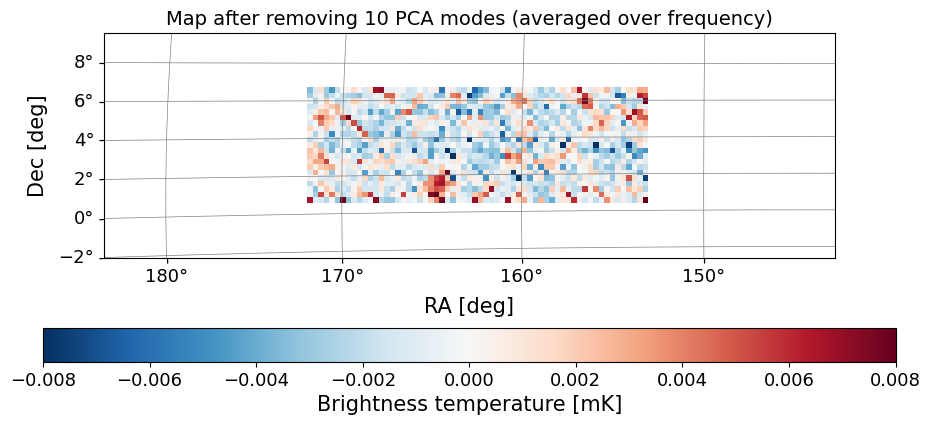

In [8]:
N_fg = 10 # number of principal components removed
MKmap_clean, A_mat = pca_clean(MKmap_orig,N_fg,weights=ps.w_HI,mean_center=True, return_A=True) # weights: map weights; mean_center: subtract the mean in each channel; return_A: also return the removed modes
fig = plt.figure(figsize=(11, 4.5))
ax = fig.add_subplot(projection=ps.wproj)
plot_map(MKmap_clean*1e3,ps.wproj,W=ps.W_HI,cbar_label='Brightness temperature [mK]',
         vmin=-0.008,vmax=0.008,cmap='RdBu_r', # colour range [mK], a few outlier pixels are saturated; diverging colour map
         title=f'Map after removing {N_fg} PCA modes (averaged over frequency)',ax=ax)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
plt.show()

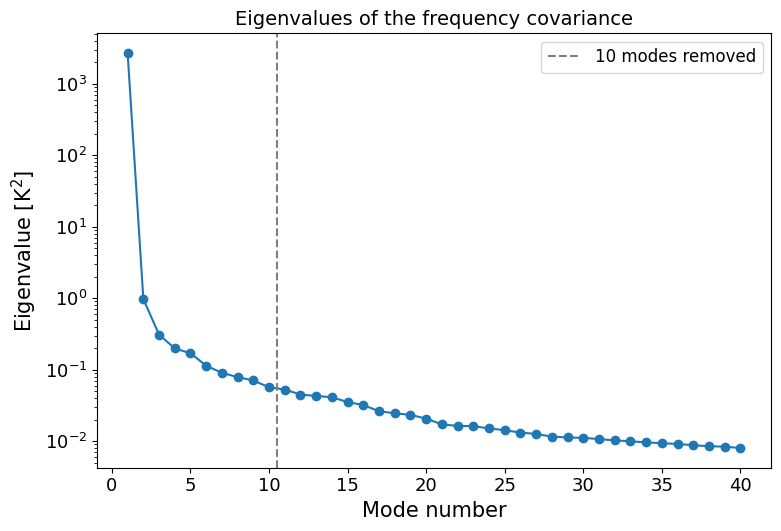

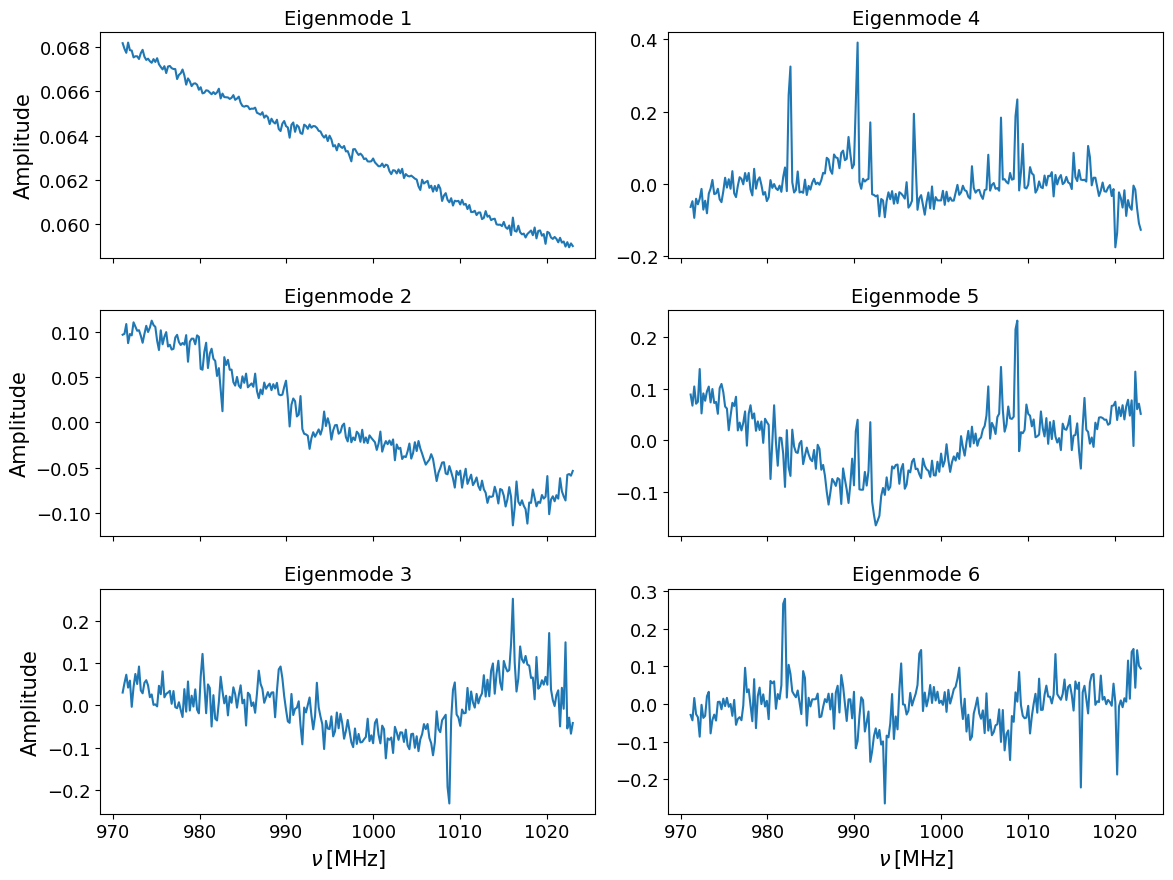

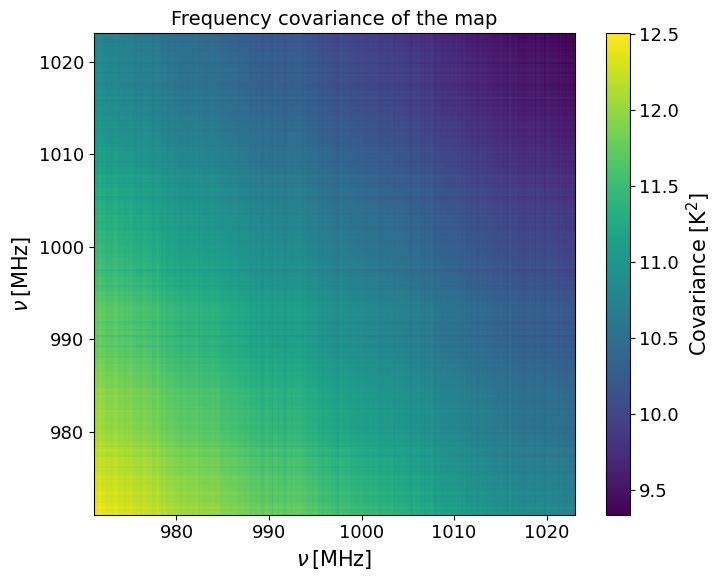

In [9]:
nu_edges = center_to_edges(ps.nu)
cov_map,eignumb,eigenval,V = pca_clean(MKmap_orig,N_fg=1,weights=ps.W_HI,return_analysis=True,mean_center=True) # return_analysis: return the frequency covariance, eigenvalues and eigenvectors # weights included in covariance calculation
plot_eigenspectrum(np.array([eigenval]), eignumb=eignumb) # eignumb: mode numbers, starting from 1
plt.axvline(N_fg + 0.5, color='grey', ls='--', label=f'{N_fg} modes removed') # ls: line style
plt.xlabel('Mode number')
plt.ylabel(r'Eigenvalue [${\rm K}^2$]')
plt.title('Eigenvalues of the frequency covariance')
plt.legend()
plt.tight_layout()
plt.show()

Num = 6 # number of eigenmodes to plot
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True) # sharex: same x-axis for all panels
for i, ax in enumerate(axes.T.ravel()):
    ax.plot(ps.nu/1e6,V[:,i])
    ax.set_title('Eigenmode %s'%(i+1))
for ax in axes[-1]:
    ax.set_xlabel(r'$\nu\,[{\rm MHz}]$')
for ax in axes[:,0]:
    ax.set_ylabel('Amplitude')
fig.tight_layout()
plt.show()

plt.figure(figsize=(7.5, 6))
plt.pcolormesh(nu_edges/1e6,nu_edges/1e6,cov_map)
plt.colorbar(label=r'Covariance [${\rm K}^2$]') # label: colour-bar label
plt.gca().set_aspect('equal')
plt.xlabel(r'$\nu\,[{\rm MHz}]$')
plt.ylabel(r'$\nu\,[{\rm MHz}]$')
plt.title('Frequency covariance of the map')
plt.tight_layout()
plt.show()

## 3. Grid the maps and galaxies onto a regular box

In [10]:
ps.data = MKmap_clean
# specify some scaling factor
ps.downres_factor_transverse = 1.5 # box cell size relative to the map pixel size, transverse
ps.downres_factor_radial = 10.0 # box cell size relative to the channel width, along the line of sight
#ps.box_buffkick = [-10,-30,-20]
ps.box_buffkick = [20,20,0] # extra padding of the box in each direction [Mpc]
ps.num_particle_per_pixel = 1 # sampling points per map pixel when gridding
ps.grid_scheme = 'nnb' # nearest-grid-point assignment
ps.get_enclosing_box() # get the minimum enclosing box for the survey lightcone
ps.box_len, ps.box_resol


(array([230.91364218, 629.00778801, 283.28714617]),
 array([13.58315542, 13.38314443, 10.49211652]))

In [11]:
hi_map_rg,hi_weights_rg,pixel_counts_hi_rg =  ps.grid_data_to_field()

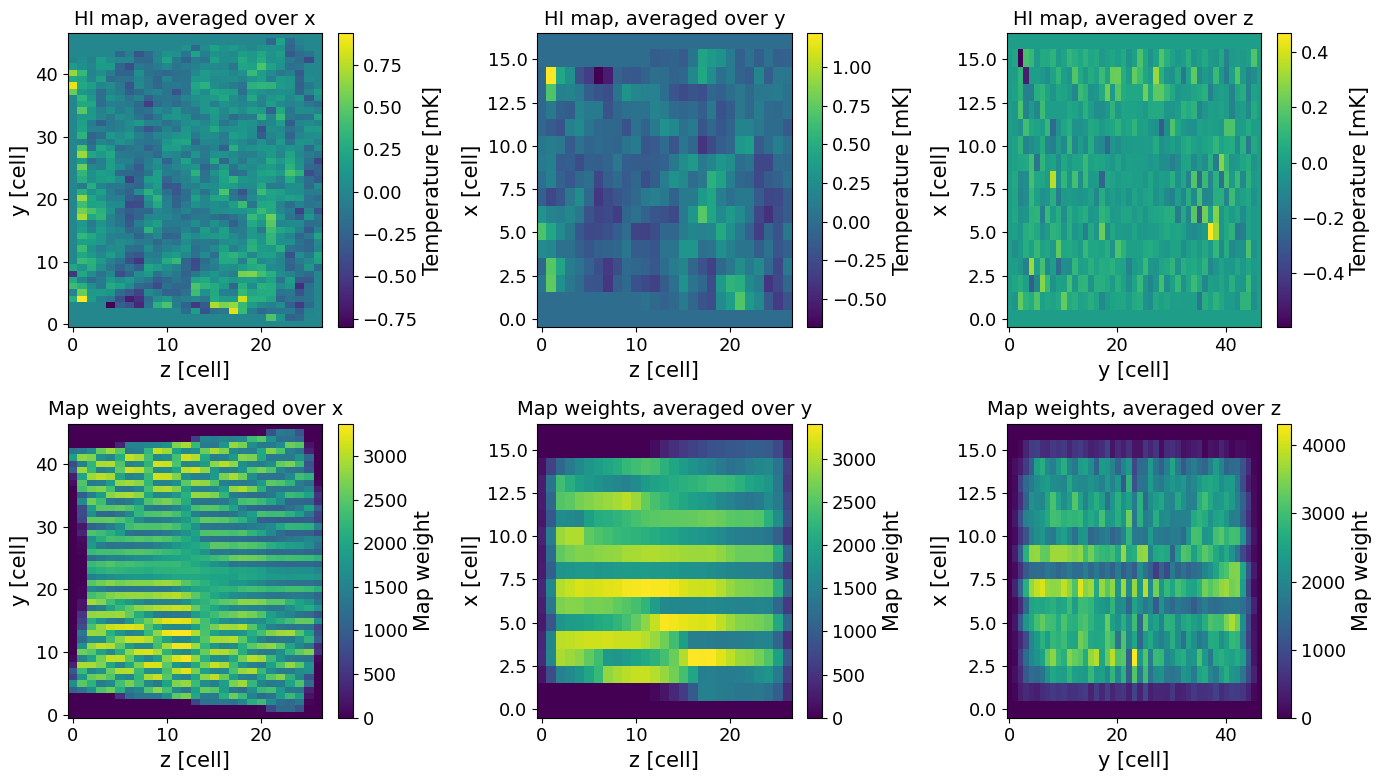

In [12]:
### Gridding sanity-check: the gridded HI map and map weights, averaged along each box axis (z is along the line of sight)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axis_names = ['x', 'y', 'z']
for i in range(3):
    rest = [axis_names[j] for j in range(3) if j != i] # the two axes left after averaging
    im = axes[0,i].imshow(
        hi_map_rg.mean(axis=i)*1e3,interpolation='none', # interpolation: no smoothing between cells
        aspect='auto', # fill the panel
        origin='lower', # first cell at the bottom left
    )
    fig.colorbar(im, ax=axes[0,i], label='Temperature [mK]') # ax: panel the colour bar belongs to
    axes[0,i].set_title(f'HI map, averaged over {axis_names[i]}')
    im = axes[1,i].imshow(
        ps.counts_in_box.mean(axis=i),interpolation='none',
        aspect='auto',
        origin='lower',
    )
    fig.colorbar(im, ax=axes[1,i], label='Map weight')
    axes[1,i].set_title(f'Map weights, averaged over {axis_names[i]}')
    for row in range(2):
        axes[row,i].set_xlabel(f'{rest[1]} [cell]')
        axes[row,i].set_ylabel(f'{rest[0]} [cell]')
fig.tight_layout()
plt.show()

In [13]:
gal_map_rg,gal_weights_rg,pixel_counts_gal_rg =  ps.grid_gal_to_field()


## 4. Power spectra

In [14]:
ps.field_1 = hi_map_rg.copy() # field 1: gridded HI map
ps.weights_grid_1 = ps.counts_in_box.astype('float') # weights of field 1 on the grid
ps.weights_field_1 = None # no extra field weights
#ps.weights_1 = (pixel_counts_hi_rg>0).astype('float')
ps.field_2 = gal_map_rg # field 2: gridded galaxy counts
ps.weights_field_2 = (ps.counts_in_box>0).astype('float')
ps.weights_grid_2 = np.ones_like(gal_map_rg)
ps.mean_center_1 = False # the field is already mean centered
ps.mean_center_2 = True # galaxy count is not
ps.unitless_1 = False # HI field is in temperature unit, does not need to 1/\bar{\pho}
ps.unitless_2 = True # galaxy count to overdensity needs 1/\bar{n}
ps.sampling_resol = np.array([ # resolution of the sky sampling [Mpc]
        ps.pix_resol_in_mpc,
        ps.pix_resol_in_mpc,
        ps.los_resol_in_mpc,
])
ps.compensate = True # correct for the gridding window
ps.include_sky_sampling = [True, False] # account for map pixelisation for HI only
ps.apply_taper_to_field(1, axis=[2,]) # apply taper to field 1 (HI) along the line of sight
ps.apply_taper_to_field(2, axis=[2,]) # apply taper to field 2 (galaxies) along the line of sight



In [15]:
nkbin = 11
# in h/Mpc
kmin,kmax = 0.07,0.3
kbins = np.linspace(kmin,kmax,nkbin+1) # k-bin edges [using linear binning]
# in Mpc-1
kbins *= ps.h
# in h/Mpc
kcuts = [0.02,0.02,0.25,0.25] #[kperpmin,kparamin,kperpmax,kparamax] (exclude areas of k-space from spherical average)
# in Mpc-1
kcuts = np.array(kcuts) * ps.h
k_sel = np.ones_like(ps.k_mode)
k_sel[0] = 0.0
k_sel[:,0,:] = 0.0
k_sel[:,:,0] = 0.0
k_sel *= (
    (np.abs(ps.k_perp<=kcuts[2]) * np.abs(ps.k_perp>kcuts[0]))[:,:,None] *
    (np.abs(ps.k_para<=kcuts[3]) * np.abs(ps.k_para>kcuts[1]))[None,None]
).astype('float')
ps.k1dbins = kbins # k-bin edges for the 1D power spectrum


In [16]:
ps.tracer_bias_2 = 1.3 # galaxy bias
ps.tracer_bias_1 = 1.5 # HI bias
ps.omega_hi = 5e-4 # HI density
ps.mean_amp_1 = 'average_hi_temp' # field 1 is in temperature, scaled by the mean HI temperature

In [17]:
pdata_1d_cross,keff_c,nmodes_c = ps.get_1d_power(ps.cross_power_3d,k1dweights=k_sel) # k1dweights: which k-modes enter the average
pdata_1d_gg,keff_gg,nmodes_gg = ps.get_1d_power(ps.auto_power_3d_2,k1dweights=k_sel)
pdata_1d_hi,keff_hi,nmodes_hi = ps.get_1d_power(ps.auto_power_3d_1,k1dweights=k_sel)
pmod_1d_gg,keff_gg,nmodes_gg = ps.get_1d_power(ps.auto_power_tracer_2_model,k1dweights=k_sel)
# shot noise for galaxy auto-power
psn = get_shot_noise_galaxy(gal_map_rg, ps.box_len, ps.weights_grid_2 * ps.weights_field_2) * shot_noise_correction_from_gridding(ps.box_ndim,ps.grid_scheme)
psn_1d_gg,_,_ = ps.get_1d_power(psn,k1dweights=k_sel)

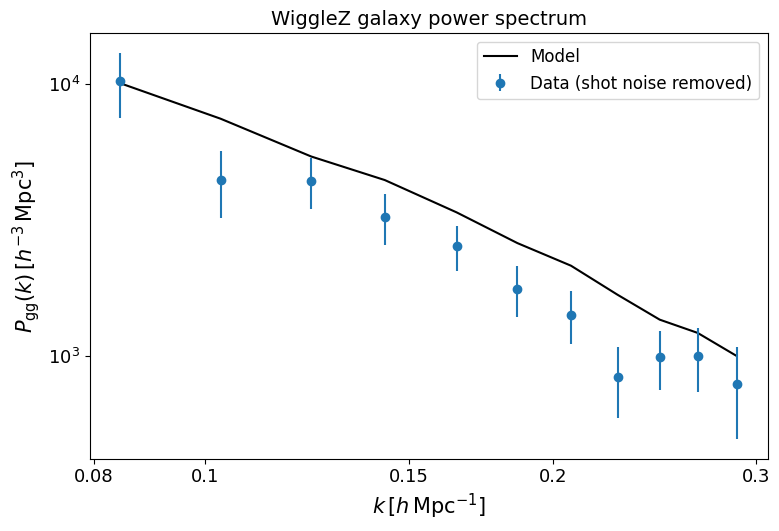

In [18]:
# a naive error bar 
perror_1d_gg = (pdata_1d_gg)/np.sqrt(nmodes_gg)

plt.figure()
plt.plot(keff_gg/ps.h,pmod_1d_gg*ps.h**3,label='Model',color='black')
plt.errorbar(keff_gg/ps.h,(pdata_1d_gg-psn_1d_gg)*ps.h**3,
             yerr=perror_1d_gg*ps.h**3,
             ls='none',
             marker='o',
             label='Data (shot noise removed)')

plt.xscale('log')
plt.yscale('log')
plt.xticks([0.08, 0.1, 0.15, 0.2, 0.3], ['0.08', '0.1', '0.15', '0.2', '0.3']) # plain tick labels on the log axis
plt.minorticks_off()
plt.legend()
plt.xlabel(r'$k\,[h\,{\rm Mpc}^{-1}]$')
plt.ylabel(r'$P_{\rm gg}(k)\,[h^{-3}\,{\rm Mpc}^3]$')
plt.title('WiggleZ galaxy power spectrum')
plt.tight_layout()
plt.show()

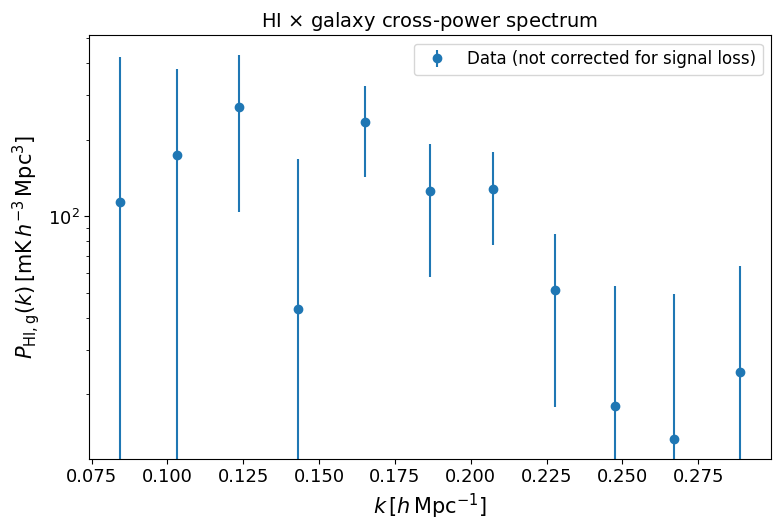

In [19]:
# a naive error bar 
perror_1d_c = np.sqrt((pdata_1d_cross**2 + pdata_1d_hi * pdata_1d_gg)/2)/np.sqrt(nmodes_c)

plt.figure()
#plt.plot(keff/ps.h,pmod_1d_gg*ps.h**3,label='model')
plt.errorbar(keff_c/ps.h,(pdata_1d_cross)*ps.h**3*1e3, # power in mK
             yerr=perror_1d_c*ps.h**3*1e3,
             ls='none',
             marker='o',
             label='Data (not corrected for signal loss)')

#plt.xscale('log')
#plt.yscale('symlog',linthresh=1e-1)
plt.yscale('log')
plt.legend()
plt.xlabel(r'$k\,[h\,{\rm Mpc}^{-1}]$')
plt.ylabel(r'$P_{\rm HI,g}(k)\,[{\rm mK}\,h^{-3}\,{\rm Mpc}^3]$')
plt.title(r'HI $\times$ galaxy cross-power spectrum')
plt.tight_layout()
plt.show()

Cylindrical power spectrum, in bins of $k_\perp$ and $k_\parallel$.

In [20]:
ps.kperpbins = np.linspace(0, 0.3, 11) # k_perp bin edges
ps.kparabins = np.linspace(0, 0.3, 11) # k_para bin edges

In [21]:
pcross_cy,_ = ps.get_cy_power(ps.cross_power_3d)

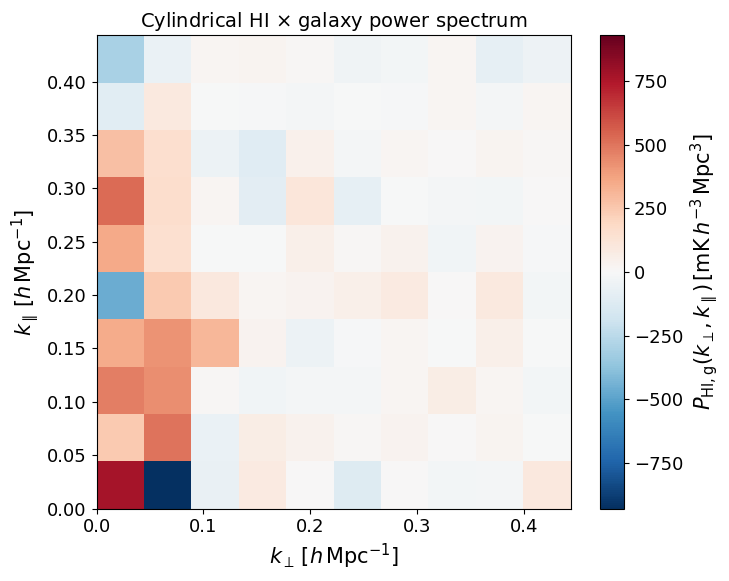

In [22]:
# axes in h/Mpc and power in mK h^-3 Mpc^3, same colour scale as -3 to 3 K Mpc^3
cy_scale = ps.h**3*1e3
plt.figure(figsize=(7.5, 6))
plt.pcolormesh(ps.kperpbins/ps.h,ps.kparabins/ps.h,(pcross_cy.T)*cy_scale,cmap='RdBu_r',vmin=-3*cy_scale,vmax=3*cy_scale) # cmap: colour map; vmin, vmax: colour range
plt.colorbar(label=r'$P_{\rm HI,g}(k_\perp,k_\parallel)\,[{\rm mK}\,h^{-3}\,{\rm Mpc}^3]$')
plt.xlabel(r'$k_\perp\,[h\,{\rm Mpc}^{-1}]$')
plt.ylabel(r'$k_\parallel\,[h\,{\rm Mpc}^{-1}]$')
plt.title(r'Cylindrical HI $\times$ galaxy power spectrum')
plt.tight_layout()
plt.show()

## 5. Transfer function

Mock HI signal is injected into the uncleaned maps and the PCA cleaning is redone, to measure the signal lost in cleaning. This runs 100 null-test and 100 cross-power realisations and is the slowest part of the notebook. Set `num_process` to the number of CPU cores you have.

In [23]:
import multiprocessing as mp

mp.set_start_method("spawn", force=True)
# pass the ps specficiations as well as some simulation settings
tf = TransferFunction(
    ps, N_fg=N_fg, # power spectrum settings; number of PCA modes removed
    # generate mock data on a high-resolution grid, then to average it to sky map for injection
    highres_sim=2, upres_transverse=2, upres_radial=2,
    uncleaned_data=MKmap_orig, # inject into the map data to reperform PCA
    num_process=8, # number of available cpus to run parallel calculation
    pca_map_weights=ps.w_HI.astype('float'), # map weights used in the PCA
)
# run a null test as well, 100 realisations
null_test_arr = tf.run(range(100), type='null', return_power_3d=False) # realisation seeds; type of run; do not return the 3D power
# run tf calculation
results_arr = tf.run(range(100), type='cross', return_power_3d=False, return_power_1d=True) # return_power_1d: also return the mock 1D power before and after cleaning

In [24]:
# organise the results of 100 realisations
tf_1d_arr = []
pnull_1d_arr = []
pmock_1d_cross_arr = []
pmock_1d_cross_cleaned_arr = []
for i in range(len(results_arr)):
    tf_1d_arr.append(results_arr[i][0])
    pnull_1d_arr.append(null_test_arr[i][0])
    pmock_1d_cross_arr.append(results_arr[i][1])
    pmock_1d_cross_cleaned_arr.append(results_arr[i][2])

tf_1d_arr = np.array(tf_1d_arr)
pnull_1d_arr = np.array(pnull_1d_arr)
pmock_1d_cross_arr = np.array(pmock_1d_cross_arr)
pmock_1d_cross_cleaned_arr = np.array(pmock_1d_cross_cleaned_arr)

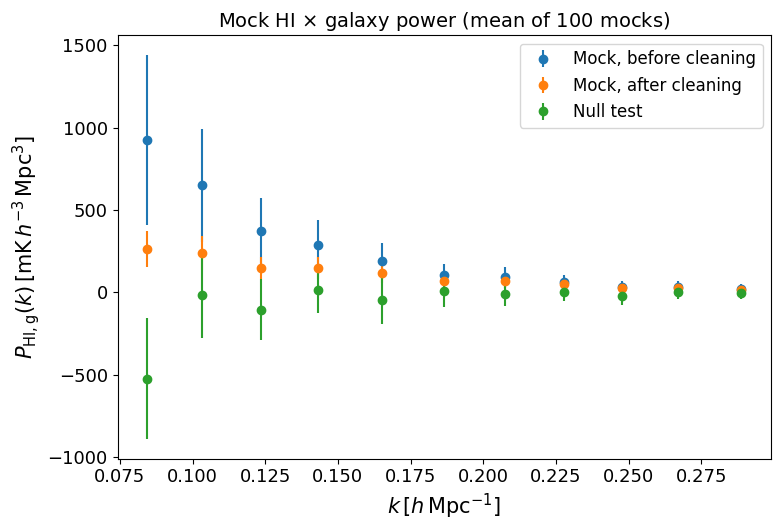

In [25]:
plt.figure()
plt.errorbar(keff_c/ps.h,(pmock_1d_cross_arr).mean(0)*ps.h**3*1e3, # power in mK
             yerr=pmock_1d_cross_arr.std(0)*ps.h**3*1e3,
             ls='none',
             marker='o',
             label='Mock, before cleaning')
plt.errorbar(keff_c/ps.h,(pmock_1d_cross_cleaned_arr).mean(0)*ps.h**3*1e3,
             yerr=pmock_1d_cross_cleaned_arr.std(0)*ps.h**3*1e3,
             ls='none',
             marker='o',
             label='Mock, after cleaning')
plt.errorbar(keff_c/ps.h,(pnull_1d_arr).mean(0)*ps.h**3*1e3,
             yerr=pnull_1d_arr.std(0)*ps.h**3*1e3,
             ls='none',
             marker='o',
             label='Null test')
#plt.xscale('log')
#plt.yscale('symlog',linthresh=1e-2)
#plt.yscale('log')
plt.legend()
plt.xlabel(r'$k\,[h\,{\rm Mpc}^{-1}]$')
plt.ylabel(r'$P_{\rm HI,g}(k)\,[{\rm mK}\,h^{-3}\,{\rm Mpc}^3]$')
plt.title(r'Mock HI $\times$ galaxy power (mean of 100 mocks)')
plt.tight_layout()
plt.show()

In [26]:
tf_1d_mean = np.mean(tf_1d_arr, axis=0)
# a naive error bar
perror_1d_tf = np.sqrt((pdata_1d_cross**2/tf_1d_mean**2 + pdata_1d_hi * pdata_1d_gg/tf_1d_mean)/2)/np.sqrt(nmodes_c-1)
# correlation matrix
corr_mat_tf = np.corrcoef((1/tf_1d_arr).T)
cov_mat_tf = corr_mat_tf * perror_1d_tf[:,None] * perror_1d_tf[None,:]

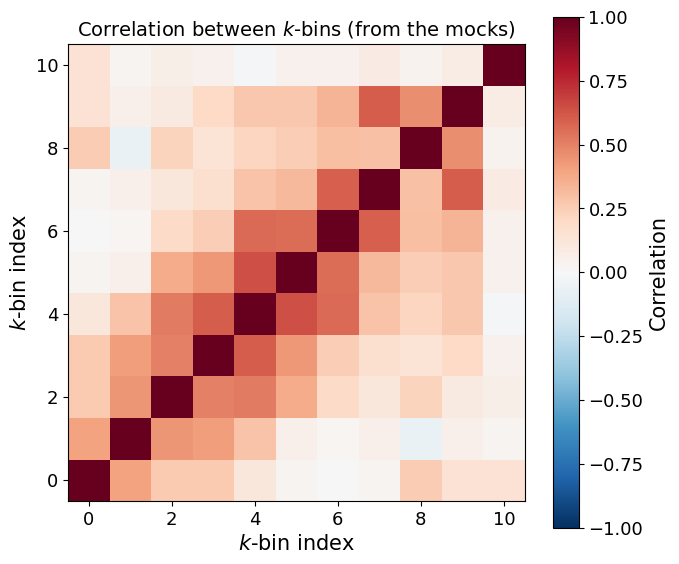

In [27]:
plt.figure(figsize=(7, 6))
plt.imshow(corr_mat_tf, vmin=-1, vmax=1,cmap='RdBu_r', origin='lower')
plt.colorbar(label='Correlation')
plt.xlabel('$k$-bin index')
plt.ylabel('$k$-bin index')
plt.title('Correlation between $k$-bins (from the mocks)')
plt.tight_layout()
plt.show()

Cross-power spectrum corrected for the transfer function, compared with the null test.

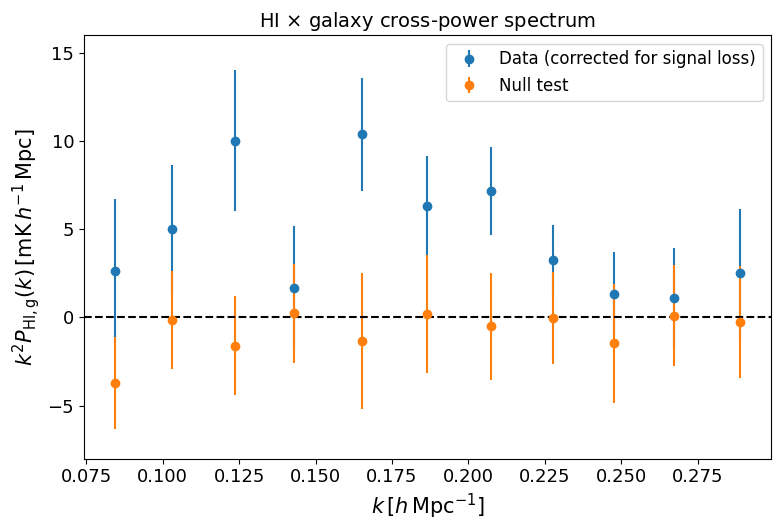

In [28]:
k_factor = keff_c**2 / ps.h**2 * 1e3 # k^2 in h^2/Mpc^2, and K to mK
#plt.plot(keff_c/ps.h, pmod_1d_c*ps.h**3 * k_factor)
plt.figure()
plt.errorbar(keff_c/ps.h,(pdata_1d_cross/tf_1d_mean)*ps.h**3 * k_factor,
             yerr= (perror_1d_tf)*ps.h**3 * k_factor,
             ls='none',
             marker='o',
             label='Data (corrected for signal loss)')

plt.errorbar(keff_c/ps.h,(pnull_1d_arr).mean(0)*ps.h**3 * k_factor,
             yerr=pnull_1d_arr.std(0)*ps.h**3 * k_factor,
             ls='none',
             marker='o',
             label='Null test')
plt.axhline(y=0, color='black', linestyle='--')
plt.ylim(-8,16) # y-range [mK h^-1 Mpc]
#plt.yscale('log')
plt.legend()
plt.xlabel(r'$k\,[h\,{\rm Mpc}^{-1}]$')
plt.ylabel(r'$k^2 P_{\rm HI,g}(k)\,[{\rm mK}\,h^{-1}\,{\rm Mpc}]$')
plt.title(r'HI $\times$ galaxy cross-power spectrum')
plt.tight_layout()
plt.show()

Compare with the model cross-power spectrum.

In [29]:
pmod_1d_c,_,_ = ps.get_1d_power(ps.cross_power_tracer_model,k1dweights=k_sel)

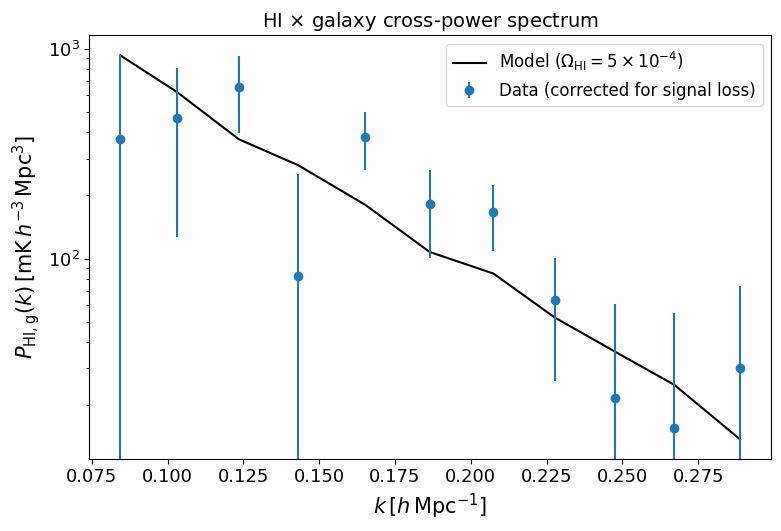

In [30]:
# check the power spectrum in volume unit:
k_factor = 1e3 # K to mK
plt.figure()
plt.plot(keff_c/ps.h, pmod_1d_c*ps.h**3 * k_factor, color='black', label=r'Model ($\Omega_{\rm HI}=5\times10^{-4}$)')
plt.errorbar(keff_c/ps.h,(pdata_1d_cross/tf_1d_mean)*ps.h**3 * k_factor,
             yerr= perror_1d_tf*ps.h**3 * k_factor,
             ls='none',
             marker='o',
             label='Data (corrected for signal loss)')
plt.yscale('log')
#plt.ylim(1e1,5e3)
plt.legend()
plt.xlabel(r'$k\,[h\,{\rm Mpc}^{-1}]$')
plt.ylabel(r'$P_{\rm HI,g}(k)\,[{\rm mK}\,h^{-3}\,{\rm Mpc}^3]$')
plt.title(r'HI $\times$ galaxy cross-power spectrum')
plt.tight_layout()
plt.show()

## 6. Detection significance and parameter fit

The detection significance is $\sqrt{\mathbf{d}^T C^{-1} \mathbf{d}}$ for data vector $\mathbf{d}$ and covariance $C$.

In [31]:
data_vector = (pdata_1d_cross/tf_1d_mean)
data_covariance = cov_mat_tf
np.sqrt(data_vector @ np.linalg.inv(data_covariance) @ data_vector)

np.float64(4.45227295151526)

In [32]:
data_vector = (pdata_1d_cross/tf_1d_mean)
data_covariance = cov_mat_tf
# fit two parameters, overall HI density and beam size
# init position
ps.omega_hi = 5e-4
ps.sigma_beam_ch = ps.sigma_beam_ch.mean()
# tell sampler which parameters to vary
varied_params = ['omega_hi', 'sigma_beam_ch']
# specify priors
params_priors = [
    ('uniform', 1e-4, 2e-3), # flat prior, lower, upper
    # gaussian prior, mean, sigma
    ('gaussian', ps.sigma_beam_ch.mean(), 0.1), # beam model should be close to truth since it is a measurement

]
# here we use emcee-sampler
sampler = SamplerEmcee(
    extract_model_fitting_inputs(ps), 
    data_vector, # measured cross-power, corrected for the transfer function
    data_covariance, # its covariance
    params_name=varied_params, # parameters varied in the fit
    params_prior=params_priors, # their priors
    observables=['cross'], # only fit cross power
    save=True, # save the chain to disk
    save_filename='fitting2.h5', # file for the chain
    nwalkers=4, # number of walkers
    nsteps=200, # steps per walker
    nthreads=8, # number of parallel processes
)

In [33]:
init_pos = np.array([5e-4, ps.sigma_beam_ch.mean()])
start_coord = (
    1 + np.random.uniform(-1e-2, 1e-2, size=(sampler.nwalkers, sampler.ndim))
) * init_pos[None, :]

In [34]:
# resume = True if you are starting from a previous run
sampler.run(resume=False, progress=True, start_coord=start_coord) # progress: show a progress bar; start_coord: starting walker positions

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 1/200 [00:06<21:47,  6.57s/it]

  1%|          | 2/200 [00:08<13:17,  4.03s/it]

  2%|▏         | 3/200 [00:11<10:31,  3.21s/it]

  2%|▏         | 4/200 [00:13<09:13,  2.82s/it]

...

 98%|█████████▊| 197/200 [07:52<00:07,  2.56s/it]

 99%|█████████▉| 198/200 [07:55<00:05,  2.60s/it]

100%|█████████▉| 199/200 [07:57<00:02,  2.44s/it]

100%|██████████| 200/200 [08:00<00:00,  2.50s/it]

100%|██████████| 200/200 [08:00<00:00,  2.40s/it]

In [35]:
# posterior
points = sampler.get_points().reshape((-1,2))
points[:,0] = points[:,0]*1e3

In [36]:
log_prob = sampler.get_log_prob()
best_fit = sampler.get_points().reshape((-1,2))[np.argmax(sampler.get_log_prob())]

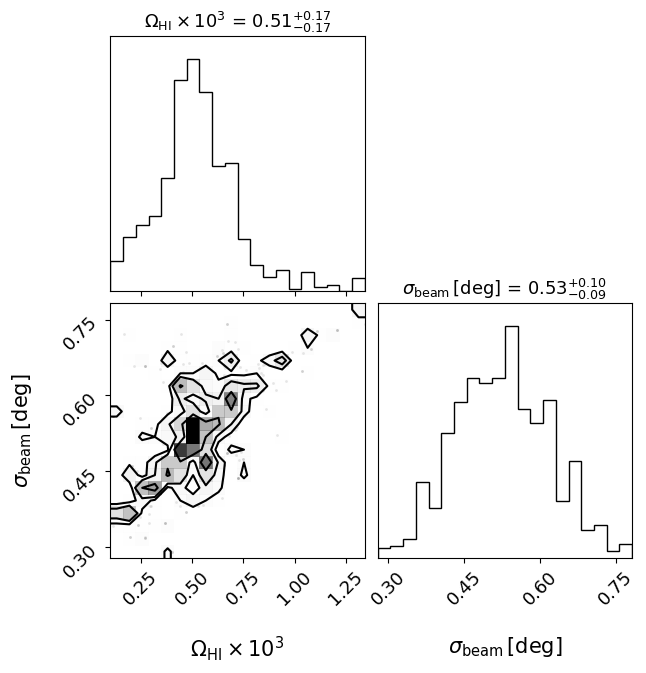

In [37]:
import corner
corner.corner(
    points,
    labels=[r'$\Omega_{\rm HI}\times 10^3$', r'$\sigma_{\rm beam}\,[{\rm deg}]$'], # axis labels
    show_titles=True, # show the median and 68% range above each panel
    fig=plt.figure(figsize=(7, 7)), # figure to draw on
    label_kwargs={'fontsize': 15}, # axis-label font size
    title_kwargs={'fontsize': 13}, # title font size
);
plt.show()

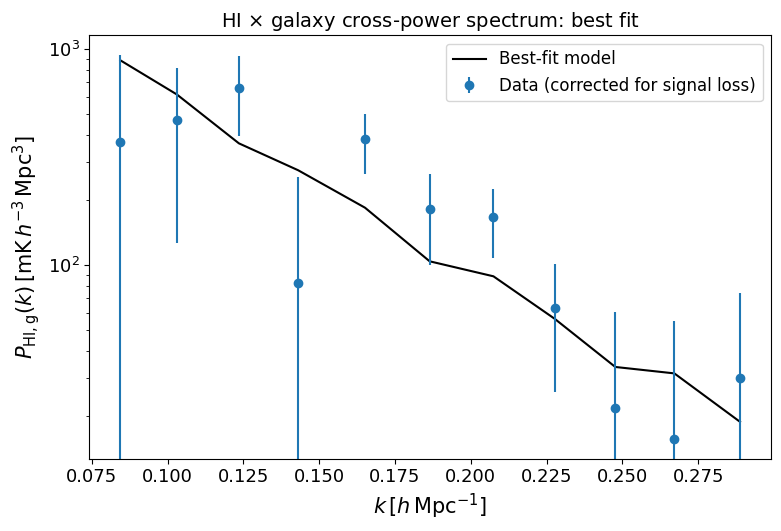

In [38]:
# a naive error bar 
#k_factor = keff_c**2 / ps.h**2
k_factor = 1e3 # K to mK
plt.figure()
plt.plot(keff_c/ps.h, sampler.get_model_vector(best_fit)[0]*ps.h**3 * k_factor,label='Best-fit model',color='black')
plt.errorbar(keff_c/ps.h,(pdata_1d_cross/tf_1d_mean)*ps.h**3 * k_factor,
             yerr= perror_1d_tf*ps.h**3 * k_factor,
             ls='none',
             marker='o',
             label='Data (corrected for signal loss)')
plt.yscale('log')
#plt.ylim(1e1,9e3)
plt.legend()
plt.xlabel(r'$k\,[h\,{\rm Mpc}^{-1}]$')
plt.ylabel(r'$P_{\rm HI,g}(k)\,[{\rm mK}\,h^{-3}\,{\rm Mpc}^3]$')
plt.title(r'HI $\times$ galaxy cross-power spectrum: best fit')
plt.tight_layout()
plt.show()